# 01 · Style definition and success metric

This notebook settles the two definitions that everything else depends on:

1. **What is a style?** The unit we predict. Each style needs a stable, unique `style_id` for the API.
2. **What makes a style successful?** The quantity the model will learn to predict.

Each decision comes with the evidence from the data that supports it.

**Data used:** `articles.csv` and `transactions_train.csv`. `customers.csv` isn't required by the brief;
customer behaviour can be derived from `customer_id` in transactions.

**Excluded:** non-fashion product groups (Items, Cosmetic, Furniture, Garment and Shoe care, Interior textile, Stationery, Fun). Together they are ~0.01% of revenue and have no style to predict.

**Excluded:** non-fashion product groups (Items, Cosmetic, Furniture, Garment and Shoe care, Interior textile, Stationery, Fun). Together they are ~0.01% of revenue and have no style to predict.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_science").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_science.data import load_articles, load_transactions
from data_science.features.style import STYLE_ATTRIBUTES, GROUP_ATTRIBUTES, add_style_columns, make_id
from data_science.features.success import success_scores

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
articles = load_articles()
tx = load_transactions(columns=["t_dat", "article_id", "price"])
tx = tx[tx.article_id.isin(articles.article_id)]   # drop non-fashion articles (see note above)
tx = tx[tx.article_id.isin(articles.article_id)]   # drop non-fashion articles (see note above)
print(f"articles:     {len(articles):,} rows")
print(f"transactions: {len(tx):,} rows, {tx.t_dat.min().date()} → {tx.t_dat.max().date()}")

articles:     105,444 rows


transactions: 31,780,277 rows, 2018-09-20 → 2020-09-22


## 1. The tables

### `articles.csv`: one row per article (one product in one colour)

Most attributes come in pairs: a code (`_no` / `_id` / `_code`) and its label (`_name`).

In [3]:
overview = pd.DataFrame({
    "unique values": articles.nunique(),
    "missing": articles.isna().sum(),
    "example": articles.iloc[0],
})
overview

,unique values,missing,example
article_id,105444,0,108775015
product_code,47148,0,0108775
prod_name,45808,0,Strap top
product_type_no,113,0,253
product_type_name,113,0,Vest top
product_group_name,12,0,Garment Upper body
graphical_appearance_no,30,0,1010016
graphical_appearance_name,30,0,Solid
colour_group_code,50,0,9
colour_group_name,50,0,Black


### `transactions_train.csv`: one row per unit sold

There is no quantity column, so each row is one unit. `price` is scaled by Kaggle (not a currency), so
only comparisons between prices are meaningful. Stock, returns and promotions aren't available.

In [4]:
print(f"articles sold at least once: {tx.article_id.nunique():,} of {len(articles):,}")
tx.price.describe().to_frame("price").T

articles sold at least once: 104,452 of 105,444


,count,mean,std,min,25%,50%,75%,max
price,31780277.0,0.027834,0.019181,0.000017,0.015831,0.025407,0.033881,0.591525


## 2. Defining a style

A style is the set of attributes that **together define a customer's style choice**. It has to be:

- **Exhaustive**: changing any attribute *outside* the set doesn't change the style.
- **Non-redundant**: changing the value of any attribute *inside* the set gives a different style.

### 2.1 Which columns duplicate others?

If column A determines column B (each A value maps to one B value), B adds no information once A is included.

In [5]:
def determines(a, b):
    n_values = articles.groupby(a)[b].nunique()
    return f"{(n_values > 1).sum()} of {len(n_values)} {a} values map to >1 {b}"

pairs = [("product_type_name", "product_group_name"),
         ("index_name", "index_group_name"),
         ("colour_group_name", "perceived_colour_master_name"),
         ("colour_group_name", "perceived_colour_value_name"),
         ("graphical_appearance_no", "graphical_appearance_name")]
for a, b in pairs:
    print(determines(a, b))

0 of 113 product_type_name values map to >1 product_group_name
0 of 10 index_name values map to >1 index_group_name
40 of 50 colour_group_name values map to >1 perceived_colour_master_name
43 of 50 colour_group_name values map to >1 perceived_colour_value_name
0 of 30 graphical_appearance_no values map to >1 graphical_appearance_name


- `product_type` → `product_group`: fully determined, so **`product_group` is a duplicate**.
- `index` → `index_group`: `index_group` is a coarser version. The extra splits in `index` (accessories, lingerie) are already captured by product type.
- `graphical_appearance_no` ↔ `_name`: one-to-one, so they're interchangeable.
- `colour_group` does **not** determine colour tone, so tone may add information. Checked below.

### 2.2 Column-by-column verdict

| Column | Verdict | Reason |
|---|---|---|
| `article_id`, `product_code`, `prod_name` | ❌ identifiers | name a product, not a style |
| `product_group_name` | ❌ duplicate | determined by product type |
| `index_name` | ❌ duplicate | finer version of index group; extra splits covered by product type |
| `perceived_colour_master_name` | ❌ duplicate | colour family; `colour_group_name` is finer |
| `department_name`, `section_name` | ❌ internal organisation | buying teams and store layout; customers don't see them |
| `garment_group_name` | ❌ unreliable | mixes fabric, type and labels like "Special Offers"; many "Unknown" |
| **`index_group_name`** | ✅ who it is for | Ladieswear / Menswear / Divided / Baby-Children / Sport |
| **`product_type_name`** | ✅ what it is | dress, trousers, hoodie, ... |
| **`graphical_appearance_name`** | ✅ surface design | pattern and texture |
| **`colour_group_name`** | ✅ colour | 50 specific colours |
| **`perceived_colour_value_name`** | ✅ tone | dark / light / dusty light / bright, ... |

### 2.3 Does colour tone add anything beyond the colour itself?

In [6]:
tone = pd.crosstab(articles.colour_group_name, articles.perceived_colour_value_name, normalize="index")
colours = ["Black", "White", "Dark Blue", "Light Pink", "Red", "Blue", "Pink", "Yellow", "Green"]
tone.loc[colours].round(2)

perceived_colour_value_name,Bright,Dark,Dusty Light,Light,Medium,Medium Dusty,Undefined,Unknown
colour_group_name,,,,,,,,
Black,0.00,1.00,0.00,0.00,0.00,0.00,0.0,0.0
White,0.00,0.00,0.02,0.98,0.00,0.00,0.0,0.0
Dark Blue,0.04,0.80,0.00,0.00,0.04,0.12,0.0,0.0
Light Pink,0.00,0.00,0.74,0.23,0.03,0.00,0.0,0.0
Red,0.47,0.01,0.00,0.00,0.49,0.04,0.0,0.0
Blue,0.04,0.00,0.10,0.12,0.18,0.57,0.0,0.0
Pink,0.08,0.00,0.22,0.07,0.28,0.35,0.0,0.0
Yellow,0.20,0.04,0.04,0.00,0.56,0.17,0.0,0.0
Green,0.19,0.00,0.41,0.05,0.06,0.29,0.0,0.0


In [7]:
dominant_share = (articles.groupby("colour_group_name").perceived_colour_value_name
                  .agg(lambda v: v.value_counts().iloc[0]).sum() / len(articles))
print(f"articles whose tone is the most common tone for their colour: {dominant_share:.1%}")

articles whose tone is the most common tone for their colour: 79.5%


For most colours the tone is fixed (Black → Dark, White → Light), so it adds nothing there and does no harm.
Where it varies, the split is meaningful: **Red is split between Medium and Bright** (classic vs neon red), and
**Light Pink between Dusty Light and Light** (muted vs clean pastel). Tone stays in.

### 2.4 Is "who it is for" needed?

Without `index_group_name`, would men's, women's and kids' products end up in the same style?

In [8]:
no_segment = [c for c in STYLE_ATTRIBUTES if c != "index_group_name"]
key = make_id(articles, no_segment)
segments_per_style = articles.groupby(key).index_group_name.nunique()
mixed = segments_per_style[segments_per_style > 1].index
print(f"styles without segment: {key.nunique():,}")
print(f"styles mixing >1 customer segment: {len(mixed):,}, "
      f"covering {key.isin(mixed).mean():.0%} of articles")

examples = (articles[key.isin(mixed)].assign(style=key)
            .groupby("style").index_group_name.value_counts().unstack(fill_value=0))
examples.loc[examples.sum(axis=1).nlargest(5).index]

styles without segment: 15,932
styles mixing >1 customer segment: 4,783, covering 80% of articles


index_group_name,Baby/Children,Divided,Ladieswear,Menswear,Sport
style,,,,,
trousers__solid__black__dark,269,228,689,235,111
dress__solid__black__dark,58,362,877,0,0
dress__all-over-pattern__black__dark,41,306,421,0,0
jacket__solid__black__dark,162,167,228,145,62
sweater__solid__black__dark,46,239,297,146,30


Most articles would sit in styles that mix customer segments. A parent buying kids' trousers would never
consider men's trousers instead, so segment changes the purchase decision. **It is part of the style.**

### 2.5 Final style definition

Data-quality fix: `product_type_name` contains both "Dog Wear" and "Dog wear". Values that differ only in
case are merged to their most common spelling, so the same style can't get two names.

In [9]:
styled = add_style_columns(articles)

assert styled.groupby("style_id").style_name.nunique().max() == 1
assert styled.groupby("style_name").style_id.nunique().max() == 1

per_style = styled.groupby("style_id").size()
print(f"styles: {styled.style_id.nunique():,}   groups (index_group + product_type): {styled.group_id.nunique()}")
print(f"articles per style: median {per_style.median():.0f}, mean {per_style.mean():.1f}, max {per_style.max()}")
styled[["article_id", *STYLE_ATTRIBUTES, "style_id"]].head(3)

styles: 23,674   groups (index_group + product_type): 347
articles per style: median 1, mean 4.5, max 877


,article_id,index_group_name,product_type_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,style_id
0,108775015,Ladieswear,Vest top,Solid,Black,Dark,ladieswear__vest-top__solid__black__dark
1,108775044,Ladieswear,Vest top,Solid,White,Light,ladieswear__vest-top__solid__white__light
2,108775051,Ladieswear,Vest top,Stripe,Off White,Dusty Light,ladieswear__vest-top__stripe__off-white__dusty-light


`style_id` is a readable slug, e.g. `ladieswear__dress__all-over-pattern__light-pink__dusty-light`. It is
unique, it's built only from article attributes (so it doesn't change when the model is retrained), and it is URL-safe.

### 2.6 Why not articles or product codes?

Next season's products mostly don't exist yet. How many of the articles and styles that sold in one season
also sold in the same season a year later?

In [10]:
def sold_in(start, end):
    w = tx[(tx.t_dat >= start) & (tx.t_dat <= end)]
    return set(w.article_id.unique())

style_of = styled.set_index("article_id").style_id
a18, a19 = sold_in("2018-09-23", "2018-12-15"), sold_in("2019-09-23", "2019-12-15")
s18, s19 = set(style_of.loc[list(a18)]), set(style_of.loc[list(a19)])
print(f"Autumn 2019 articles that also sold in Autumn 2018: {len(a19 & a18) / len(a19):.0%}")
print(f"Autumn 2019 styles   that also sold in Autumn 2018: {len(s19 & s18) / len(s19):.0%}")

w19 = tx[(tx.t_dat >= "2019-09-23") & (tx.t_dat <= "2019-12-15")]
rev_old_articles = w19.loc[w19.article_id.isin(a18), "price"].sum() / w19.price.sum()
rev_old_styles = w19.loc[w19.article_id.map(style_of).isin(s18), "price"].sum() / w19.price.sum()
print(f"Autumn 2019 revenue from articles that existed in Autumn 2018: {rev_old_articles:.0%}")
print(f"Autumn 2019 revenue from styles   that existed in Autumn 2018: {rev_old_styles:.0%}")

Autumn 2019 articles that also sold in Autumn 2018: 31%
Autumn 2019 styles   that also sold in Autumn 2018: 61%


Autumn 2019 revenue from articles that existed in Autumn 2018: 16%
Autumn 2019 revenue from styles   that existed in Autumn 2018: 86%


Most articles are new each season (only 16% of Autumn 2019 revenue came from articles sold a year earlier),
but 86% of revenue came from styles that already existed a year earlier. The styles that don't recur are mostly tiny. That makes styles the right unit for a *next-season* prediction.

### 2.7 Known gap

Fit, length, neckline and fabric clearly affect a customer's choice, but they only exist in the free-text
`detail_desc` (and in images), not in structured columns. Extracting them would push the number of styles
towards one style per product, which brings back the sparsity and turnover problem. They are left out and noted as a limitation.

In [11]:
articles.loc[articles.product_type_name.isin(["Dress", "Trousers"]), ["product_type_name", "detail_desc"]].sample(4, random_state=1)

,product_type_name,detail_desc
8771,Dress,Calf-length dress in marled cotton jersey with short sleeves. Elasticated se...
2212,Trousers,Shaping. 5-pocket jeans in washed denim with technical stretch that holds in...
35296,Dress,"Sleeveless, knee-length dress in pleated jersey with a sheen. Round neckline..."
59929,Dress,"Knee-length dress in an airy weave with a V-neck, wrapover front with ties a..."


## 3. Defining a successful style

The goal isn't to find the best-selling products. It's to find **which styles perform best**. The metric should:

- reward **revenue** (how much the style earned),
- penalise **discounting** (selling at full price shows real demand),
- remove the **inherent demand of the category** (trousers sell more than gloves whatever their style),
- **not depend on how many styles a category has.**

### 3.1 The formula (per style, per 12-week season)

```
Adjusted revenue = Revenue × (Revenue ÷ Full-price revenue)
Group benchmark  = Σ Adjusted revenue² ÷ Σ Adjusted revenue    (over styles in the same index_group + product_type)
Success score    = Adjusted revenue ÷ Group benchmark
```

- **Full-price revenue** is what the units would have earned at each article's highest observed price.
- **Group benchmark** is the revenue-weighted typical style size of the category: each style counts in
  proportion to its revenue, so a long tail of tiny styles barely moves it.
- **A score of 1** means "as good as the typical style a sale in this category comes from"; 2 means twice that.
- **No minimum-size floor.** Every style gets a score, including very small ones (see 3.5).

### 3.2 Is the highest price a safe "full price"?

In [12]:
p = tx.groupby("article_id").price.agg(["max", "median"])
(p["max"] / p["median"]).quantile([.5, .9, .99]).rename("max ÷ median price per article").to_frame().T.round(2)

,0.50,0.90,0.99
max ÷ median price per article,1.0,1.86,2.89


For a typical article the highest price equals its median price, and even at the 99th percentile it's
under 3×. There are no extreme outliers, so the maximum is a reasonable estimate of the undiscounted price.

### 3.3 Scores on three past seasons

In [13]:
SEASONS = {
    "Summer 2019": ("2019-06-30", "2019-09-22"),
    "Autumn 2019": ("2019-09-23", "2019-12-15"),
    "Summer 2020": ("2020-06-30", "2020-09-22"),
}
scores = {name: success_scores(tx, styled, *window) for name, window in SEASONS.items()}
for name, s in scores.items():
    print(f"{name}: {len(s):,} styles sold")

Summer 2019: 12,612 styles sold
Autumn 2019: 11,933 styles sold
Summer 2020: 12,494 styles sold


In [14]:
cols = ["style_name", "success_score", "full_price_factor", "revenue", "units", "articles", "group_styles"]
s = scores["Summer 2020"]
print("Summer 2020: top 15 styles by success score")
s[cols].head(15).round(2)

Summer 2020: top 15 styles by success score


,style_name,success_score,full_price_factor,revenue,units,articles,group_styles
0,Ladieswear · Skirt · Solid · Black · Dark,4.50,0.74,288.769989,8166,104,229
1,Baby/Children · Sweater · All over pattern · Light Beige · Dusty Light,4.11,0.96,5.080000,331,13,282
2,Baby/Children · Dress · Solid · Light Pink · Dusty Light,4.06,0.91,6.890000,282,25,199
3,Baby/Children · T-shirt · Solid · White · Light,3.79,0.89,5.800000,478,38,277
4,Baby/Children · Sweater · Solid · Black · Dark,3.63,0.90,4.780000,245,17,282
5,Baby/Children · Leggings/Tights · Solid · Black · Dark,3.55,0.94,7.010000,397,37,111
6,Ladieswear · Dress · Solid · Black · Dark,3.51,0.78,1970.189941,57001,464,381
7,Divided · Sweater · Solid · Black · Dark,3.44,0.90,239.479996,9721,90,197
8,Ladieswear · Blazer · Solid · Black · Dark,3.41,0.93,570.739990,10852,40,115
9,Menswear · Sweater · Solid · Black · Dark,3.33,0.97,77.260002,3138,37,123


In [15]:
print("Summer 2020: top 10 by raw revenue, for comparison")
s.nlargest(10, "revenue")[cols].round(2)

Summer 2020: top 10 by raw revenue, for comparison


,style_name,success_score,full_price_factor,revenue,units,articles,group_styles
6,Ladieswear · Dress · Solid · Black · Dark,3.51,0.78,1970.189941,57001,464,381
13,Ladieswear · Trousers · Solid · Black · Dark,3.14,0.88,1777.670044,50547,335,244
112,Divided · Trousers · Denim · Blue · Medium Dusty,1.99,0.95,1058.800049,22593,94,137
123,Divided · Trousers · Solid · Black · Dark,1.94,0.96,1017.049988,32522,103,137
99,Ladieswear · Bra · Solid · Black · Dark,2.07,0.85,917.150024,38325,215,102
15,Ladieswear · Sweater · Solid · Black · Dark,3.09,0.97,905.229980,23964,113,225
46,Ladieswear · Jacket · Solid · Black · Dark,2.44,0.95,886.950012,9487,88,105
28,Ladieswear · Blouse · Solid · White · Light,2.86,0.71,800.979980,33227,246,239
315,Ladieswear · Dress · All over pattern · Black · Dark,1.37,0.77,779.099976,21165,210,381
81,Ladieswear · Underwear bottom · Solid · Black · Dark,2.17,0.95,746.270020,38095,183,101


Raw revenue puts only Ladieswear basics at the top. The success score spreads the leaders across categories
and customer segments.

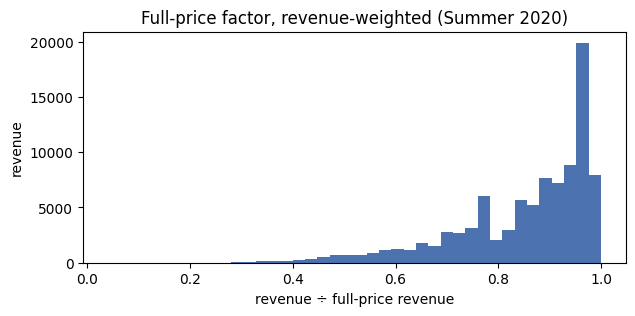

In [16]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(s.full_price_factor, bins=40, weights=s.revenue, color="#4C72B0")
ax.set(title="Full-price factor, revenue-weighted (Summer 2020)", xlabel="revenue ÷ full-price revenue", ylabel="revenue")
plt.show()

### 3.4 Is the score independent of the number of styles in a category?

Revenue **share** (style revenue ÷ category revenue) was rejected because shares in a category always add
up to 100%: a category with many styles gives each style a smaller share. Below: the top score in each
category against the category's number of styles (categories with ≥5 styles).

Summer 2019: Spearman with #styles: top success score +0.87, top share -0.62
Autumn 2019: Spearman with #styles: top success score +0.83, top share -0.51
Summer 2020: Spearman with #styles: top success score +0.85, top share -0.60


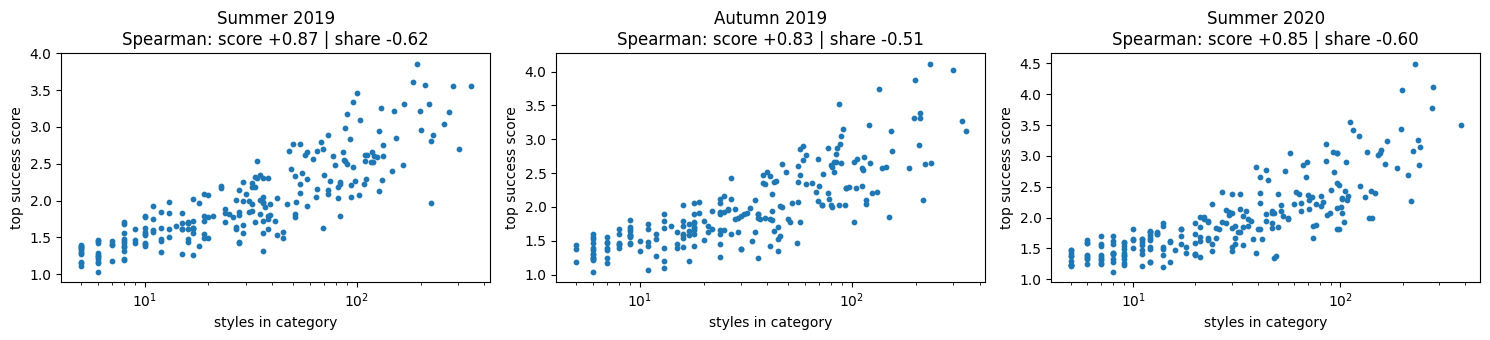

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, s_) in zip(axes, scores.items()):
    s_ = s_.assign(share=s_.revenue / s_.groupby("group_id").revenue.transform("sum"))
    g = s_.groupby("group_id").agg(n=("group_styles", "first"), top_score=("success_score", "max"), top_share=("share", "max"))
    g = g[g.n >= 5]
    r_score = g.top_score.corr(g.n, method="spearman")
    r_share = g.top_share.corr(g.n, method="spearman")
    print(f"{name}: Spearman with #styles: top success score {r_score:+.2f}, top share {r_share:+.2f}")
    ax.scatter(g.n, g.top_score, s=10)
    ax.set(xscale="log", title=f"{name}\nSpearman: score {r_score:+.2f} | share {r_share:+.2f}",
           xlabel="styles in category", ylabel="top success score")
plt.tight_layout(); plt.show()

Share is strongly *negatively* related to the number of styles, as expected. The success score is
*positively* related: a dominant basic stands out more against a category full of mid-sized styles.
Neither is fully independent. The success score is kept because it works on the same scale across categories
(revenue-weighted average = 1 in every category). This is recorded as a limitation.

### 3.5 Very small styles: no floor

In [18]:
for name, s_ in scores.items():
    top = s_.head(50)
    print(f"{name}: {(top.articles < 5).sum()} of the top 50 styles have fewer than 5 articles")
print("\nSummer 2019: top 10")
scores["Summer 2019"][cols].head(10).round(2)

Summer 2019: 1 of the top 50 styles have fewer than 5 articles
Autumn 2019: 3 of the top 50 styles have fewer than 5 articles
Summer 2020: 2 of the top 50 styles have fewer than 5 articles

Summer 2019: top 10


,style_name,success_score,full_price_factor,revenue,units,articles,group_styles
0,Ladieswear · Skirt · Solid · Black · Dark,3.86,0.88,512.349976,12645,98,193
1,Menswear · Sweater · Solid · Black · Dark,3.62,0.90,57.209999,2016,60,185
2,Divided · Sweater · Solid · Black · Dark,3.57,0.79,217.479996,10504,117,211
3,Ladieswear · Dress · Solid · Black · Dark,3.56,0.82,1967.959961,59551,388,344
4,Ladieswear · Sweater · Solid · Black · Dark,3.56,0.83,583.080017,21019,120,285
5,Baby/Children · Jumpsuit/Playsuit · Solid · Off White · Dusty Light,3.46,0.93,4.900000,156,2,100
6,Ladieswear · Scarf · Solid · Black · Dark,3.35,0.91,19.740000,712,12,96
7,Menswear · Shirt · Solid · White · Light,3.32,0.82,120.070000,3934,56,168
8,Baby/Children · Dress · Solid · Black · Dark,3.31,0.89,6.260000,223,20,220
9,Ladieswear · Bikini top · Solid · Black · Dark,3.25,0.68,717.719971,38661,100,130


A few very small styles rank highly, e.g. a Baby/Children jumpsuit with 2 articles and 156 units in Summer 2019.
**They are kept.** If a style does far better than the typical style in its category, it performed well,
however few articles it had.

The real question is whether that success **repeats** next season. With 1–2 articles, a high score may come
from one specific hit product rather than from the style's attributes, and that product won't exist next season.
That is exactly what the prediction model learns from history. If small styles' success doesn't carry over,
the model will score them lower, and time-based validation will show it. The number of articles will be
given to the model as a feature. No arbitrary threshold is needed.

Small-revenue styles with many articles also rank highly, e.g. several Baby/Children styles in Summer 2020.
That's intended: they outperform their own category, and kids' categories simply earn less.

### 3.6 Alternative tested and rejected: leave-one-out benchmark

The benchmark includes the style itself, so a strong style raises its own benchmark (a style that
dominates its category scores ≈ 1). A leave-one-out benchmark, built only from the *other* styles, removes this.

In [19]:
def leave_one_out(s_):
    a = s_.adjusted_revenue
    g = s_.groupby("group_id").adjusted_revenue
    sum_a, sum_a2 = g.transform("sum"), g.transform(lambda x: (x ** 2).sum())
    bench = ((sum_a2 - a ** 2) / (sum_a - a)).where(s_.group_styles > 1)
    return s_.assign(loo_score=a / bench)

loo = leave_one_out(scores["Summer 2020"])
single = loo[loo.group_styles == 1]
print(f"single-style categories (cannot be scored): {len(single)}, {single.revenue.sum() / loo.revenue.sum():.2%} of revenue")
print("\nunfiltered top 5 by leave-one-out score:")
display(loo.nlargest(5, "loo_score")[["style_name", "loo_score", "revenue", "articles", "group_styles"]].round(1))
f = loo[(loo.group_styles >= 10) & (loo.articles >= 5)]
print("with floors (≥10 styles in category, ≥5 articles):")
f.nlargest(10, "loo_score")[["style_name", "loo_score", "revenue", "articles", "group_styles"]].round(1)

single-style categories (cannot be scored): 41, 0.11% of revenue

unfiltered top 5 by leave-one-out score:


,style_name,loo_score,revenue,articles,group_styles
552,Divided · Ballerinas · Solid · Black · Dark,103.900002,1.800000,2,2
544,Divided · Boots · Solid · Black · Dark,100.599998,21.500000,21,4
548,Menswear · Earring · Solid · Silver · Light,76.300003,0.300000,2,2
537,Menswear · Bra · Solid · White · Light,39.700001,1.400000,1,2
284,Ladieswear · Ballerinas · Solid · Black · Dark,31.799999,67.800003,27,39


with floors (≥10 styles in category, ≥5 articles):


,style_name,loo_score,revenue,articles,group_styles
284,Ladieswear · Ballerinas · Solid · Black · Dark,31.799999,67.800003,27,39
327,Ladieswear · Leggings/Tights · Solid · Black · Dark,30.600000,517.400024,81,48
275,Ladieswear · Underwear Tights · Solid · Black · Dark,18.200001,82.199997,46,24
207,Divided · Bag · Solid · Black · Dark,18.100000,67.099998,51,38
255,Sport · Trousers · Solid · Black · Dark,17.700001,95.900002,35,30
138,Ladieswear · Bag · Solid · Black · Dark,17.000000,237.399994,50,74
322,Ladieswear · Flat shoe · Solid · Black · Dark,15.600000,64.199997,34,21
274,Divided · Leggings/Tights · Solid · Black · Dark,13.700000,99.699997,22,30
16,Baby/Children · Shirt · Solid · White · Light,13.700000,9.100000,37,92
238,Divided · Coat · Solid · Black · Dark,13.000000,37.400002,5,17


Leave-one-out gives extreme scores (> 100) in categories with only 2–3 styles. Even with floors, the winners
become "default colour" categories: black ballerinas, leggings and tights, where customers barely buy any other
colour. **The inclusive benchmark is kept**, and the self-inclusion effect is noted as a limitation.

### 3.7 Is it predictable?

In [20]:
def compare(a, b, k=50):
    x = scores[a][["style_id", "success_score"]]
    y = scores[b][["style_id", "success_score"]]
    m = x.merge(y, on="style_id", suffixes=("_a", "_b"))
    overlap = len(set(x.head(k).style_id) & set(y.head(k).style_id))
    return {"from": a, "to": b, "common styles": len(m),
            "Spearman": round(m.success_score_a.corr(m.success_score_b, method="spearman"), 2),
            f"top-{k} overlap": f"{overlap}/{k}"}

pd.DataFrame([compare("Summer 2019", "Autumn 2019"), compare("Summer 2019", "Summer 2020"),
              compare("Autumn 2019", "Summer 2020")])

,from,to,common styles,Spearman,top-50 overlap
0,Summer 2019,Autumn 2019,9946,0.75,29/50
1,Summer 2019,Summer 2020,7478,0.53,30/50
2,Autumn 2019,Summer 2020,7679,0.51,22/50


Scores carry over from season to season to a moderate degree: enough persistence for a model to learn from,
and enough change that simply repeating last season isn't the whole answer.

### 3.8 What kind of styles win?

In [21]:
rows = []
for name, s_ in scores.items():
    top = s_.head(50)
    rows.append({"season": name, "categories in top 50": top.group_id.nunique(),
                 "Solid": top.style_name.str.contains("· Solid ·").sum(),
                 "Black": top.style_name.str.contains("· Black ·").sum()})
pd.DataFrame(rows)

,season,categories in top 50,Solid,Black
0,Summer 2019,46,41,31
1,Autumn 2019,48,41,35
2,Summer 2020,45,40,30


⚠️ **Supply vs. demand.** The winners are mostly solid black and white basics. Part of that comes from H&M's
own supply decisions: H&M offers far more articles in these styles (e.g. ~100 black solid skirts against a handful in most
other colours), so they naturally earn more in total. The score therefore partly reflects H&M's buying plan,
not only customer preference. Without stock and assortment data we can't fully separate the two. We accept
this deliberately: these styles really did perform best, and predicting what performs is the goal.

## 4. Decisions

| Decision | Choice |
|---|---|
| Style | `index_group + product_type + graphical_appearance + colour_group + perceived_colour_value` |
| `style_id` | slug of the five attributes, e.g. `ladieswear__dress__all-over-pattern__light-pink__dusty-light` |
| Success score | discount-adjusted revenue ÷ revenue-weighted category benchmark (style included) |
| Minimum size | none; the model learns whether small styles' success repeats (`articles` as a feature) |
| Known limitations | no fit/length/fabric in the style; score partly reflects supply; style counts in its own benchmark; score is not fully independent of category size |

**Next:** choose the prediction period.